## Google Drive & Data Setup

- **Environment:** Designed to run in Google Colab.
- **Model Weights:** Trained checkpoint weights (`.pth`) are stored externally on Drive and are not included directly in the Git repository.

To run this notebook successfully, ensure your Google Drive has the following folder structure:

```
MyDrive/
└── projects/
    └── aptos2019/
        ├── data/
        │   ├── raw/
        │   │   └── aptos2019/
        │   │       └── train_images/         <-- Raw labeled images from Kaggle (required if not fully bypassed)
        │   └── processed/
        │       └── aptos2019/
        │           ├── splits/               <-- CSV files: train_split.csv, val_split.csv, test_split.csv
        │           └── images_processed/     <-- Preprocessed images used by the dataset
        ├── models/                           <-- Place your trained .pth model checkpoints here
        └── figures/                          <-- Folder where generated evaluation plots will be saved
```

The notebook will automatically mount Google Drive, clone the repository, copy the processed data into the local workspace, and configure paths for checkpoints and figures.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Clone the repository
!git clone https://github.com/valeria-ltv/diabetic-retinopathy-classifier.git

# Go into the repository folder
%cd diabetic-retinopathy-classifier

# Check the commit hash
import subprocess
try:
    commit_hash = subprocess.check_output(["git", "rev-parse", "HEAD"]).decode("utf-8").strip()
    print(f"\nNotebook executed from Git commit: {commit_hash}\n")
except Exception as e:
    print("\nGit repository not detected or git command failed.\n")

# Copy processed data from Google Drive
import shutil
shutil.copytree(
    '/content/drive/MyDrive/projects/aptos2019/data/processed',
    'data/processed',
    dirs_exist_ok=True
)

# Copy raw data from Google Drive
# Uncomment if raw data is needed
# shutil.copytree(
#     '/content/drive/MyDrive/projects/aptos2019/data/raw',
#     'data/raw',
#     dirs_exist_ok=True
# )

Mounted at /content/drive
Cloning into 'diabetic-retinopathy-classifier'...
remote: Enumerating objects: 115, done.
remote: Counting objects: 100% (54/54), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 115 (delta 22), reused 47 (delta 20), pack-reused 61 (from 1)
Receiving objects: 100% (115/115), 29.05 MiB | 25.06 MiB/s, done.
Resolving deltas: 100% (42/42), done.
/content/diabetic-retinopathy-classifier

Notebook executed from Git commit: 2db4921ed26f4f75b7514a39345c54f1bfeedd9e



'data/processed'

# Model training

In [2]:
import random
import numpy as np
import pandas as pd
import time
import timm
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import resample
from scipy.optimize import minimize

from src.config import IMG_DIR, SPLITS_DIR, PROCESSED_DIR
from src.data.dataset import DiabeticRetinopathyDataset, get_dataloader

In [3]:
def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

In [4]:
MODELS_PATH = Path('/content/drive/MyDrive/projects/aptos2019/models')
FIGURES_PATH = Path('/content/drive/MyDrive/projects/aptos2019/figures')

train_df = pd.read_csv(SPLITS_DIR / "train_split.csv")
val_df = pd.read_csv(SPLITS_DIR / "val_split.csv")

train_dataset = DiabeticRetinopathyDataset(
    img_dir=str(IMG_DIR),
    annotations_df=train_df,
    split="train",
    preprocessed_dir=PROCESSED_DIR / "images_processed"
)
val_dataset = DiabeticRetinopathyDataset(
    img_dir=str(IMG_DIR),
    annotations_df=val_df,
    split="val",
    preprocessed_dir=PROCESSED_DIR / "images_processed"
)

train_loader = get_dataloader(train_dataset, batch_size=16, num_workers=2)
val_loader = get_dataloader(val_dataset, batch_size=16, num_workers=2)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


## Pretrained models comparison

Library for getting pre trained image models: timm

**Models used for comparison:** efficientnet_b0, resnet34, convnext_tiny, densenet121

**Loss function:** Cross-entropy loss

**Optimizer:** AdamW, lr = 1e-4

Train models for 5 epoch, compare QWK metric and training time. Choose model for further experiments.

In [5]:
def train(model, train_loader, loss_fn, optimizer, device):
    model.train()
    train_loss = 0.0
    total_samples = 0
    for batch in train_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        out = model(images)
        loss = loss_fn(out, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        current_batch_size = images.shape[0]
        total_samples += current_batch_size
        train_loss += loss.item() * current_batch_size

    avg_train_loss = train_loss / total_samples
    return avg_train_loss

def evaluate(model, val_loader, loss_fn, device):
    model.eval()
    val_loss = 0.0
    total_samples = 0
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for batch in val_loader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)

            out = model(images)
            loss = loss_fn(out, labels)
            current_batch_size = images.shape[0]
            total_samples += current_batch_size
            val_loss += loss.item() * current_batch_size

            preds = torch.argmax(out, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

    avg_val_loss = val_loss / total_samples
    return avg_val_loss, all_targets, all_preds

In [6]:
class ClassificationModel(nn.Module):
    def __init__(self, model_name, num_classes=5):
        super().__init__()
        self.model = timm.create_model(model_name, pretrained=True, num_classes=num_classes)

    def forward(self, x):
        return self.model(x)

In [ ]:
models_to_test = ['efficientnet_b0', 'resnet34', 'convnext_tiny', 'densenet121']
results = {}
training_times = {}

for model_name in models_to_test:
    print(f"\nTraining {model_name}:")

    set_seed()
    model = ClassificationModel(model_name=model_name).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
    loss_fn = nn.CrossEntropyLoss()

    num_epochs = 5
    best_qwk = -1.0
    start_time = time.time()
    for epoch in range(num_epochs):
        avg_train_loss = train(model, train_loader, loss_fn, optimizer, device)
        avg_val_loss, all_targets, all_preds = evaluate(model, val_loader, loss_fn, device)

        val_qwk = cohen_kappa_score(all_targets, all_preds, weights='quadratic')
        print(f"Epoch [{epoch+1}/{num_epochs}] | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Val Loss: {avg_val_loss:.4f} | "
          f"Val QWK: {val_qwk:.4f}")

        if val_qwk > best_qwk:
            best_qwk = val_qwk
            torch.save(model.state_dict(), MODELS_PATH / f'best_{model_name}.pth')

    elapsed_time = time.time() - start_time
    results[model_name] = best_qwk
    training_times[model_name] = elapsed_time
    print(f"Model {model_name} training time: {elapsed_time:.2f} seconds (~{elapsed_time/60:.1f} min)")


Training efficientnet_b0:
Epoch [1/5] | Train Loss: 0.9410 | Val Loss: 0.7453 | Val QWK: 0.7948
Epoch [2/5] | Train Loss: 0.6160 | Val Loss: 0.7314 | Val QWK: 0.7919
Epoch [3/5] | Train Loss: 0.4674 | Val Loss: 0.6119 | Val QWK: 0.8299
Epoch [4/5] | Train Loss: 0.4048 | Val Loss: 0.6254 | Val QWK: 0.8469
Epoch [5/5] | Train Loss: 0.3497 | Val Loss: 0.6151 | Val QWK: 0.8468
Model efficientnet_b0 training time: 198.80 seconds (~3.3 min)

Training resnet34:
Epoch [1/5] | Train Loss: 1.1095 | Val Loss: 0.8479 | Val QWK: 0.7326
Epoch [2/5] | Train Loss: 0.7648 | Val Loss: 0.7141 | Val QWK: 0.7558
Epoch [3/5] | Train Loss: 0.6793 | Val Loss: 0.6406 | Val QWK: 0.7891
Epoch [4/5] | Train Loss: 0.6181 | Val Loss: 0.6209 | Val QWK: 0.7766
Epoch [5/5] | Train Loss: 0.5869 | Val Loss: 0.6146 | Val QWK: 0.7447
Model resnet34 training time: 205.24 seconds (~3.4 min)

Training convnext_tiny:
Epoch [1/5] | Train Loss: 0.8330 | Val Loss: 0.6758 | Val QWK: 0.7938
Epoch [2/5] | Train Loss: 0.5997 | Val 

In [ ]:
print("\nComparison summary:")
print(f"{'Model':<16} | {'Best Val QWK':<12} | {'Train time (per epoch, sec)':<15}")
print("-" * 60)

for name, qwk in results.items():
    print(f"{name:<16} | {qwk:<12.4f} | {training_times[name]/5:<15.2f}")


Comparison summary:
Model            | Best Val QWK | Train time (per epoch, sec)
------------------------------------------------------------
efficientnet_b0  | 0.8469       | 39.76          
resnet34         | 0.7891       | 41.05          
convnext_tiny    | 0.8544       | 229.74         
densenet121      | 0.8530       | 82.25          


EfficientNet is the best for quality/speed compromise. ConvNeXt is ~6 times slower and DenseNet is ~2 times slower. ResNet34 shows worse QWK metric results than other models. For further experiments EfficientNet is chosen.

## Adding class weights for CE

Now let`s train EfficientNet for more epochs and display the confusion matrix. As our dataset is imbalanced, using weights for CE loss function may be useful to make model pay more attention to the minority class. In this approach higher weights are assigned to the minority class and lower weights to the majority class in the loss function.

In [7]:
classes = np.unique(train_df["diagnosis"].values)
print("Class frequencies:", np.bincount(train_df["diagnosis"].values))

# Inverse сlass frequency (aggressive approach)
# Penalizes errors strictly inverse to class size
# Rarest class gets 3.79x weight
weights_balanced = compute_class_weight(class_weight='balanced', classes=classes, y=train_df["diagnosis"].values)
print("Standard balanced weights:", weights_balanced)

# Inverse square root frequency (smoothed approach)
# Subdues extreme penalties using square root
# Rarest class weight is scaled down from 3.79x to a safer 1.51x
weights_smoothed = 1.0 / np.sqrt(np.bincount(train_df["diagnosis"].values))
weights_smoothed = weights_smoothed / weights_smoothed.mean()
print("Smoothed weights:", weights_smoothed)

Class frequencies: [1263  259  699  135  207]
Standard balanced weights: [0.40585907 1.97915058 0.73333333 3.79703704 2.4763285 ]
Smoothed weights: [0.49596965 1.09523394 0.66668117 1.51701506 1.22510018]


In [8]:
weights_smoothed = torch.FloatTensor(weights_smoothed).to(device)
weight_strategies = {
    "no_weights": None,
    "smoothed_weights": weights_smoothed
}

In [ ]:
num_epochs = 10
results_weights = {}

for strat_name, current_weights in weight_strategies.items():
    print(f"\nTraining efficientnet_b0 (weight strategy: {strat_name})")

    set_seed()
    model = ClassificationModel(model_name='efficientnet_b0').to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
    loss_fn = nn.CrossEntropyLoss(weight=current_weights)

    best_qwk = -1.0
    for epoch in range(num_epochs):
        avg_train_loss = train(model, train_loader, loss_fn, optimizer, device)
        avg_val_loss, all_targets, all_preds = evaluate(model, val_loader, loss_fn, device)

        val_qwk = cohen_kappa_score(all_targets, all_preds, weights='quadratic')
        print(f"Epoch [{epoch+1}/{num_epochs}] | "
              f"Train Loss: {avg_train_loss:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} | "
              f"Val QWK: {val_qwk:.4f}")

        if val_qwk > best_qwk:
            best_qwk = val_qwk
            torch.save(model.state_dict(), MODELS_PATH / f'best_effnetb0_{strat_name}.pth')

    results_weights[strat_name] = best_qwk


Training efficientnet_b0 (weight strategy: no_weights)
Epoch [1/10] | Train Loss: 0.9410 | Val Loss: 0.7453 | Val QWK: 0.7948
Epoch [2/10] | Train Loss: 0.6160 | Val Loss: 0.7314 | Val QWK: 0.7919
Epoch [3/10] | Train Loss: 0.4674 | Val Loss: 0.6119 | Val QWK: 0.8299
Epoch [4/10] | Train Loss: 0.4048 | Val Loss: 0.6254 | Val QWK: 0.8469
Epoch [5/10] | Train Loss: 0.3497 | Val Loss: 0.6151 | Val QWK: 0.8468
Epoch [6/10] | Train Loss: 0.2963 | Val Loss: 0.6219 | Val QWK: 0.8632
Epoch [7/10] | Train Loss: 0.2609 | Val Loss: 0.6936 | Val QWK: 0.8535
Epoch [8/10] | Train Loss: 0.2461 | Val Loss: 0.6163 | Val QWK: 0.8647
Epoch [9/10] | Train Loss: 0.1967 | Val Loss: 0.6051 | Val QWK: 0.8574
Epoch [10/10] | Train Loss: 0.1642 | Val Loss: 0.6704 | Val QWK: 0.8689

Training efficientnet_b0 (weight strategy: smoothed_weights)
Epoch [1/10] | Train Loss: 1.2152 | Val Loss: 1.0040 | Val QWK: 0.7856
Epoch [2/10] | Train Loss: 0.7969 | Val Loss: 0.9875 | Val QWK: 0.7969
Epoch [3/10] | Train Loss: 0.

In [ ]:
for strat, qwk in results_weights.items():
    print(f"Strategy: {strat:<12} | Best Val QWK: {qwk:.4f}")

Strategy: no_weights   | Best Val QWK: 0.8689
Strategy: smoothed_weights | Best Val QWK: 0.8676


Adding weights does not improve metric QWK, but let`s look at the confusion matrices.

In [9]:
def collect_preds(model, data_loader, device):
    model = model.to(device)
    with torch.inference_mode():
        all_probs = []
        all_preds = []
        all_targets = []
        model.eval()
        for batch in data_loader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)
            out = model(images)
            probs = torch.softmax(out, dim=1)
            preds = torch.argmax(out, dim=1)
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
    return all_targets, all_probs, all_preds

In [10]:
def plot_confusion_matrices(targets, preds, save=False, image_name="confusion_matrices"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    cm_abs = confusion_matrix(targets, preds)
    disp_abs = ConfusionMatrixDisplay(confusion_matrix=cm_abs)
    disp_abs.plot(ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title("Confusion Matrix (absolute counts)")
    axes[0].set_xlabel("Predicted label")
    axes[0].set_ylabel("True label")

    cm_norm = confusion_matrix(targets, preds, normalize="true")
    disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm)
    disp_norm.plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
    axes[1].set_title("Confusion Matrix (normalized)")
    axes[1].set_xlabel("Predicted label")
    axes[1].set_ylabel("True label")

    plt.tight_layout()
    if save:
        plt.savefig(FIGURES_PATH / f'{image_name}.png', dpi=300, bbox_inches='tight')
    plt.show()


Weight strategy: no_weights


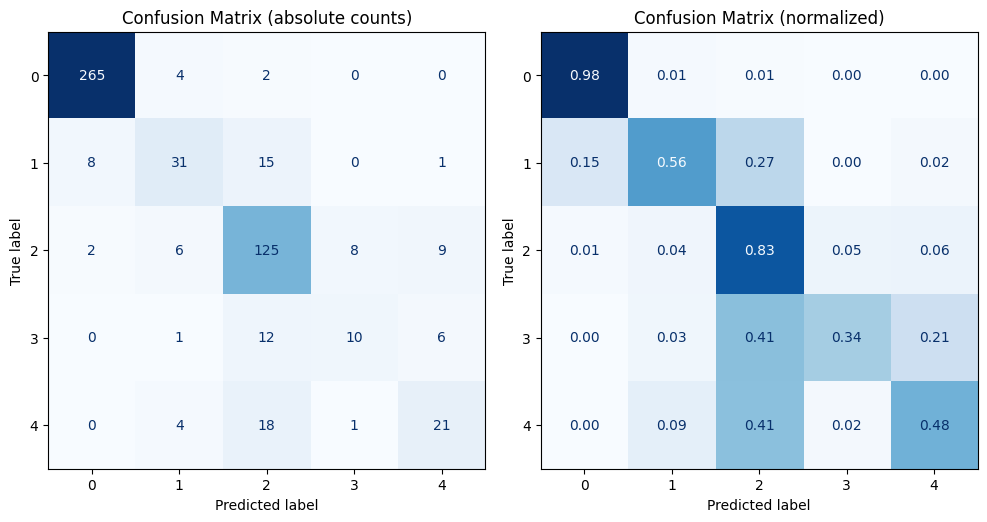


Weight strategy: smoothed_weights


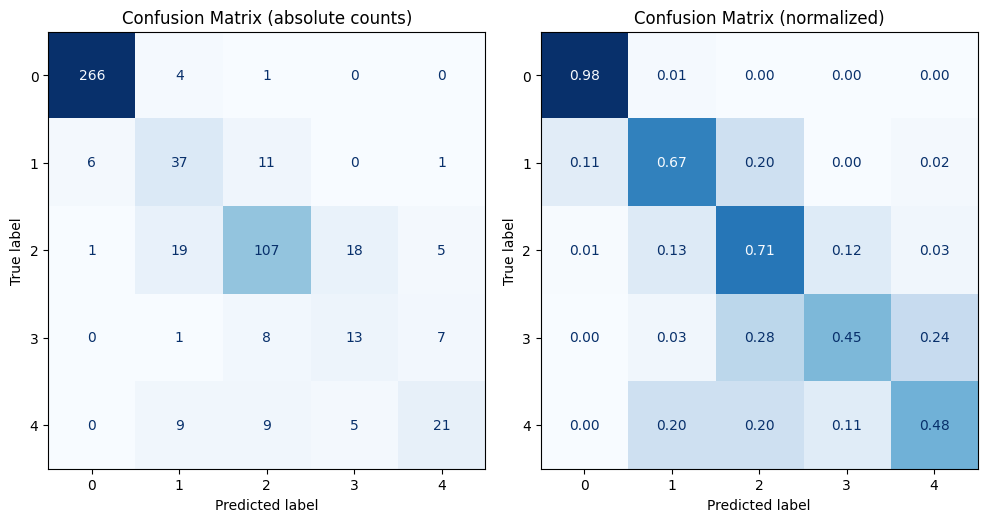

In [ ]:
for strat_name in weight_strategies:
    model = ClassificationModel(model_name="efficientnet_b0")
    target_path = MODELS_PATH / f'best_effnetb0_{strat_name}.pth'
    model.load_state_dict(torch.load(target_path, weights_only=True))
    targets, _, preds = collect_preds(model, val_loader, device)
    print(f"\nWeight strategy: {strat_name}")
    plot_confusion_matrices(targets, preds, save=True, image_name=f"effnetb0_{strat_name}_cm")

Recall for class 3 and 1 improved slightly. For class 4 the error distribution changed: mistakes spread into classes 1, 2, and 3 rather than concentrating in class 2. Сlass 2 dipped. Overall, the weights helped minority classes like class 1 and 3, but negatively impacted class 2.

## Transition to Regression

The problem with Cross-Entropy Loss is that it treats errors true 4 - predicted 1 and true 4 - predicted 3 the same, while the second situation is far more preferable. It is the essence of classification, where classes are not treated as a continuous degradation scale. Switching to regression can help to address that.

Regression loss function (MSE, MAE, HuberLoss/SmoothL1Loss, etc.) understands the scale's geometry. It penalizes the model more severely for confusing a severe stage with a mild or healthy state than for an error of a single step.

In [11]:
class RegressionModel(nn.Module):
    def __init__(self, model_name='efficientnet_b0'):
        super().__init__()
        self.model = timm.create_model(model_name, pretrained=True, num_classes=1)

    def forward(self, x):
        return self.model(x)

In [12]:
def train_reg(model, train_loader, loss_fn, optimizer, device):
    model.train()
    train_loss = 0.0
    total_samples = 0

    for batch in train_loader:
        images = batch["image"].to(device)
        labels = batch["label"].to(device)
        labels = labels.float()

        out = model(images).squeeze(1)
        loss = loss_fn(out, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        current_batch_size = images.shape[0]
        total_samples += current_batch_size
        train_loss += loss.item() * current_batch_size

    avg_train_loss = train_loss / total_samples
    return avg_train_loss

def evaluate_reg(model, val_loader, loss_fn, device):
    model.eval()
    val_loss = 0.0
    total_samples = 0
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for batch in val_loader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)
            labels = labels.float()

            out = model(images).squeeze(1)
            loss = loss_fn(out, labels)
            current_batch_size = images.shape[0]
            total_samples += current_batch_size
            val_loss += loss.item() * current_batch_size

            preds = torch.clamp(torch.round(out), 0, 4)
            all_preds.extend(preds.cpu().numpy().astype(int))
            all_targets.extend(labels.cpu().numpy().astype(int))

    avg_val_loss = val_loss / total_samples
    return avg_val_loss, all_targets, all_preds

In [ ]:
set_seed()
model = RegressionModel().to(device)
mean_label = float(train_df["diagnosis"].mean())
model.model.classifier.bias.data.fill_(mean_label)
print(f"The output layer bias is initialized with the mean label value: {mean_label:.4f}")
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
loss_fn = nn.SmoothL1Loss()

num_epochs = 20
best_val_loss = float('inf')

for epoch in (range(num_epochs)):
    avg_train_loss = train_reg(model, train_loader, loss_fn, optimizer, device)
    avg_val_loss, all_targets, all_preds = evaluate_reg(model, val_loader, loss_fn, device)

    val_qwk = cohen_kappa_score(all_targets, all_preds, weights='quadratic')
    print(f"Epoch [{epoch+1}/{num_epochs}] | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Val Loss: {avg_val_loss:.4f} | "
          f"Val QWK: {val_qwk:.4f}")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), MODELS_PATH / 'best_effnetb0_reg.pth')

The output layer bias is initialized with the mean label value: 1.1276
Epoch [1/20] | Train Loss: 1.8449 | Val Loss: 1.3234 | Val QWK: 0.4242
Epoch [2/20] | Train Loss: 1.1488 | Val Loss: 0.9910 | Val QWK: 0.5234
Epoch [3/20] | Train Loss: 0.8267 | Val Loss: 0.7393 | Val QWK: 0.6103
Epoch [4/20] | Train Loss: 0.5822 | Val Loss: 0.4730 | Val QWK: 0.6555
Epoch [5/20] | Train Loss: 0.4309 | Val Loss: 0.4149 | Val QWK: 0.6970
Epoch [6/20] | Train Loss: 0.3556 | Val Loss: 0.3507 | Val QWK: 0.7355
Epoch [7/20] | Train Loss: 0.3083 | Val Loss: 0.3963 | Val QWK: 0.6930
Epoch [8/20] | Train Loss: 0.2345 | Val Loss: 0.3815 | Val QWK: 0.7341
Epoch [9/20] | Train Loss: 0.2375 | Val Loss: 0.5261 | Val QWK: 0.6105
Epoch [10/20] | Train Loss: 0.2398 | Val Loss: 0.2383 | Val QWK: 0.8099
Epoch [11/20] | Train Loss: 0.2097 | Val Loss: 0.2157 | Val QWK: 0.8377
Epoch [12/20] | Train Loss: 0.1754 | Val Loss: 0.2935 | Val QWK: 0.7492
Epoch [13/20] | Train Loss: 0.1859 | Val Loss: 0.2846 | Val QWK: 0.7654
Ep

In [13]:
def collect_preds_reg(model, data_loader, device):
    model = model.to(device)
    with torch.inference_mode():
        all_raw_preds = []
        all_preds = []
        all_targets = []
        model.eval()
        for batch in data_loader:
            images = batch["image"].to(device)
            labels = batch["label"].to(device)
            labels = labels.float()
            out = model(images).squeeze(1)
            preds = torch.clamp(torch.round(out), 0, 4)

            all_raw_preds.extend(out.cpu().numpy())
            all_preds.extend(preds.cpu().numpy().astype(int))
            all_targets.extend(labels.cpu().numpy().astype(int))
    return all_targets, all_raw_preds, all_preds

In [ ]:
model = RegressionModel()
model.load_state_dict(torch.load(MODELS_PATH / 'best_effnetb0_reg.pth', weights_only=True))
targets, raw_preds, preds = collect_preds_reg(model, val_loader, device)

Regression model outputs continuous values (e.g., $1.34$ or $2.78$), while we  need discrete class labels ($0, 1, 2, 3, 4$) as predictions. Standard `[0.5, 1.5, 2.5, 3.5]` are naive thresholds. To maximize the QWK metric, we can perform threshold tuning and find better thresholds.

Optimization algorithm: **Nelder-Mead** simplex algorithm via `scipy.optimize.minimize`.

In [15]:
class ThresholdOptimizer:
    def __init__(self, initial_thresholds=[0.5, 1.5, 2.5, 3.5]):
        self.initial_thresholds = initial_thresholds
        self.best_thresholds = initial_thresholds

    def _apply_thresholds(self, raw_preds, thresholds):
        preds = np.zeros_like(raw_preds, dtype=int)
        for i, t in enumerate(thresholds):
            preds[raw_preds > t] = i + 1
        return preds

    def _loss_func(self, thresholds, raw_preds, targets):
        thresholds = sorted(thresholds)
        preds = self._apply_thresholds(raw_preds, thresholds)
        score = cohen_kappa_score(targets, preds, weights='quadratic')
        return -score

    def fit(self, raw_preds, targets):
        res = minimize(
            self._loss_func,
            self.initial_thresholds,
            args=(raw_preds, targets),
            method='Nelder-Mead',
        )
        self.best_thresholds = sorted(res.x)
        return self.best_thresholds

    def predict(self, raw_preds):
        return self._apply_thresholds(raw_preds, self.best_thresholds)

In [16]:
opt = ThresholdOptimizer()
raw_preds, targets = np.array(raw_preds), np.array(targets)

default_preds = opt._apply_thresholds(raw_preds, [0.5, 1.5, 2.5, 3.5])
default_qwk = cohen_kappa_score(targets, default_preds, weights='quadratic')
print(f'Val QWK (thresholds 0.5, 1.5, 2.5, 3.5): {default_qwk:.4f}')

best_thresholds = opt.fit(raw_preds, targets)
opt_preds = opt.predict(raw_preds)
opt_qwk = cohen_kappa_score(targets, opt_preds, weights='quadratic')

print(f'Optimized thresholds: {[float(round(t, 4)) for t in best_thresholds]}')
print(f'Val QWK (optimized thresholds): {opt_qwk:.4f}')

Val QWK (thresholds 0.5, 1.5, 2.5, 3.5): 0.8495
Optimized thresholds: [0.6646, 1.3483, 2.6069, 3.5752]
Val QWK (optimized thresholds): 0.8673


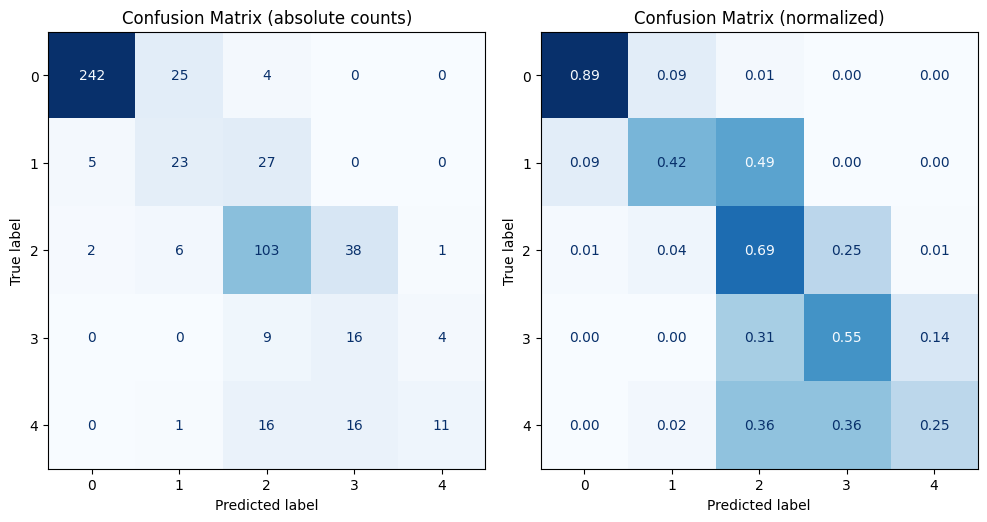

In [ ]:
plot_confusion_matrices(targets, opt_preds, save=True, image_name="effnetb0_reg_cm")

Compared to CE + smoothed weights regression shows:
1. Slightly worse recall for class 2.
2. Worse results for classes 0 (266 -> 242 out of 271), 1 (37 -> 23 out of 55) and 4 (21 -> 11 out of 44). Severe cases frequently  misclassified as class 2 or 3.
3. Slightly better recall for class 3.

Even though performance for most classes is poorer compared to classification, predictions are more concentrated around the main diagonal. As expected, the regression model captures the ordinal scale and avoids extreme misclassifications.

## Ensemble of Classification and Regression models

To leverage the strengths of both approaches (the better recall performance of classification model and the diagonal-focused predictions of the regression model) we build a hybrid ensemble.

**Steps:**

1. We convert the discrete class probabilities from the classification model into a continuous scale by computing the expected value ($EV = \sum P_i \times i$).
2. We linearly combine the classifier's expected value with the regression model's continuous predictions using a blending weight $w$.
3. The combined continuous scores are passed through our `ThresholdOptimizer` to find the decision boundaries that maximize the validation QWK score.

In [17]:
# Load models and collect predictions on validation
model_reg = RegressionModel()
model_reg.load_state_dict(torch.load(MODELS_PATH / 'best_effnetb0_reg.pth', weights_only=True))
targets_reg, raw_preds_reg, _, = collect_preds_reg(model_reg, val_loader, device)

model_class = ClassificationModel(model_name="efficientnet_b0")
model_class.load_state_dict(torch.load(MODELS_PATH / 'best_effnetb0_smoothed_weights.pth', weights_only=True))
targets_clf, probs_clf, _ = collect_preds(model_class, val_loader, device)

In [18]:
# Convert predictions and targets to numpy arrays
targets = np.array(targets_reg)
raw_preds_reg = np.array(raw_preds_reg)
val_probs = np.array(probs_clf)

# Calculate expected values for classification probabilities
class_values = np.array([0, 1, 2, 3, 4])
class_scores_from_ce = np.sum(val_probs * class_values, axis=1)

# Find for the best weight w (grid search)
best_w = 0.5
best_qwk = 0.0
best_thresholds = None
final_preds = None

for w in np.linspace(0, 1, 21):
    ensemble_raw = w * class_scores_from_ce + (1 - w) * raw_preds_reg

    # Optimize thresholds for current w
    opt = ThresholdOptimizer()
    thresholds = opt.fit(ensemble_raw, targets)
    preds = opt.predict(ensemble_raw)

    qwk = cohen_kappa_score(targets, preds, weights='quadratic')
    if qwk > best_qwk:
        best_qwk = qwk
        best_w = w
        best_thresholds = thresholds
        final_preds = preds

print(f"Best weight w: {best_w:.2f}")
print(f"Ensemble optimal thresholds: {[float(round(t, 4)) for t in best_thresholds]}")
print(f"Ensemble QWK (optimal thresholds): {best_qwk:.4f}")

Best weight w: 0.65
Ensemble optimal thresholds: [0.531, 1.5119, 2.4416, 3.4799]
Ensemble QWK (optimal thresholds): 0.8916


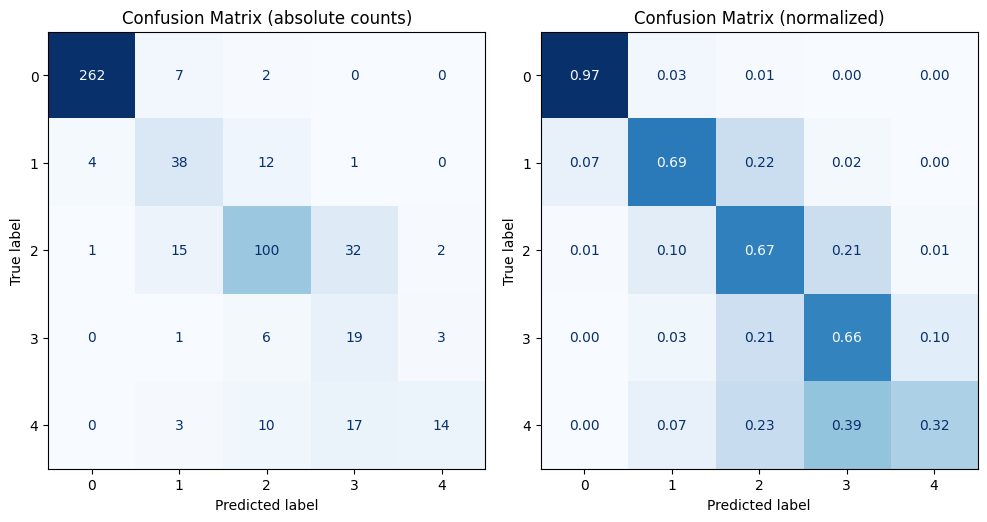

In [ ]:
plot_confusion_matrices(targets, final_preds, save=True, image_name="effnetb0_ensemble_cm")

**Ensemble results and takeaways:**
* Combining the two models increases the validation QWK to 0.8916, outperforming each individual model on its own.
* The regression component penalizes extreme misclassifications (errors of 3+ steps dropped compared to pure classification).
* While class 3 recall improved (individual 0.45 and 0.55 -> 0.66), class 4 recall experienced a trade-off (individual 0.48 and 0.25 -> 0.32).

**Note:** Since the blending weight ($w$), thresholds, and checkpoints were selected on single validation set, this score is optimistic, a completely unbiased evaluation requires a held-out test set.

# Ensemble Robustness

To evaluate the stability of the hybrid ensemble, we perform two diagnostic checks:
1. **Standard thresholds check:** Applying unoptimized, naive thresholds (`[0.5, 1.5, 2.5, 3.5]`) at the optimal weight $w = 0.65$ to check if performance relies heavily on hyper-optimized boundaries.
2. **Weight sensitivity analysis:** How does QWK change as a function of w: a plateau or a sharp peak? A broad plateau would indicate that the ensemble is stable.

In [19]:
# Check performance with standard (unoptimized) thresholds
standard_thresholds = [0.5, 1.5, 2.5, 3.5]
best_w = 0.65

def apply_thresholds(preds, thresholds):
    return np.digitize(preds, thresholds)

ensemble_raw_optimal = best_w * class_scores_from_ce + (1 - best_w) * raw_preds_reg
preds_standard = apply_thresholds(ensemble_raw_optimal, standard_thresholds)
qwk_standard = cohen_kappa_score(targets, preds_standard, weights='quadratic')

print(f"QWK with standard thresholds at w={best_w:.2f}: {qwk_standard:.4f}")

QWK with standard thresholds at w=0.65: 0.8868


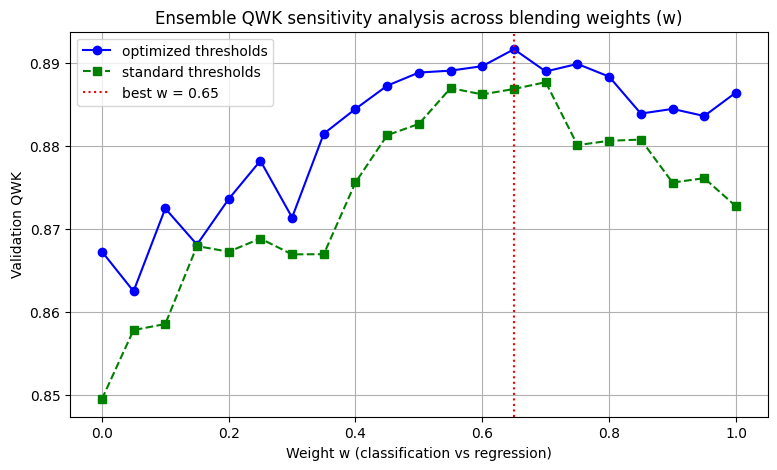

In [20]:
# Weight sensitivity analysis
weights_range = np.linspace(0, 1, 21)
qwk_optimized_list = []
qwk_standard_list = []

standard_thresholds = [0.5, 1.5, 2.5, 3.5]

for w_val in weights_range:
    raw_mix = w_val * class_scores_from_ce + (1 - w_val) * raw_preds_reg

    # Evaluate with optimized thresholds
    opt_temp = ThresholdOptimizer()
    _ = opt_temp.fit(raw_mix, targets)
    preds_opt = opt_temp.predict(raw_mix)
    qwk_optimized_list.append(cohen_kappa_score(targets, preds_opt, weights='quadratic'))

    # Evaluate with standard thresholds
    preds_std = np.digitize(raw_mix, standard_thresholds)
    qwk_standard_list.append(cohen_kappa_score(targets, preds_std, weights='quadratic'))

# Plot sensitivity curves
plt.figure(figsize=(9, 5))
plt.plot(weights_range, qwk_optimized_list, marker='o', color='b', linestyle='-', label='optimized thresholds')
plt.plot(weights_range, qwk_standard_list, marker='s', color='g', linestyle='--', label='standard thresholds')
plt.title("Ensemble QWK sensitivity analysis across blending weights (w)")
plt.xlabel("Weight w (classification vs regression)")
plt.ylabel("Validation QWK")
plt.grid(True)
plt.axvline(best_w, color='r', linestyle=':', label=f'best w = {best_w}')
plt.legend()
plt.show()

**Key takeaways from diagnostics:**
- At the optimal weight of 0.65, applying unoptimized thresholds (`[0.5, 1.5, 2.5, 3.5]`) yields a high QWK of 0.8868. It proves that the model's predictions are not highly dependent on artificial boundary overfitting.
- In the graph, both curves show a broad and stable plateau in the range
 $w \in [0.5, 0.8]$. It confirms that ensemble robust to minor weight variations.

# Final check on the test set

In [21]:
test_df = pd.read_csv(SPLITS_DIR / "test_split.csv")
test_dataset = DiabeticRetinopathyDataset(
    img_dir=str(IMG_DIR),
    annotations_df=test_df,
    split="test",
    preprocessed_dir=PROCESSED_DIR / "images_processed"
)

test_loader = get_dataloader(test_dataset, batch_size=16, num_workers=2)

In [22]:
# Load models and collect predictions on test set
model_reg = RegressionModel()
model_reg.load_state_dict(torch.load(MODELS_PATH / 'best_effnetb0_reg.pth', weights_only=True))
test_targets, test_raw_preds_reg, _ = collect_preds_reg(model_reg, test_loader, device)

model_class = ClassificationModel(model_name="efficientnet_b0")
model_class.load_state_dict(torch.load(MODELS_PATH / 'best_effnetb0_smoothed_weights.pth', weights_only=True))
_, test_probs_clf, _ = collect_preds(model_class, test_loader, device)

In [23]:
# Convert test predictions and targets to numpy arrays
test_targets = np.array(test_targets)
test_raw_preds_reg = np.array(test_raw_preds_reg)
test_probs_clf = np.array(test_probs_clf)

# Calculate expected values for classification probabilities
class_values = np.array([0, 1, 2, 3, 4])
test_class_scores = np.sum(test_probs_clf * class_values, axis=1)

# Compute ensemble raw scores using the optimal weight from validation (w = 0.65)
test_ensemble_raw = best_w * test_class_scores + (1 - best_w) * test_raw_preds_reg

# Apply thresholds optimized on the validation set
test_ensemble_preds = apply_thresholds(test_ensemble_raw, best_thresholds)

# Calculate test QWK for the ensemble and pure classification baseline
test_qwk_ensemble = cohen_kappa_score(test_targets, test_ensemble_preds, weights='quadratic')
test_qwk_ce = cohen_kappa_score(test_targets, np.argmax(test_probs_clf, axis=1), weights='quadratic')

print(f"Test QWK (pure classification): {test_qwk_ce:.4f}")
print(f"Test QWK (ensemble w={best_w}): {test_qwk_ensemble:.4f}")

# Fallback rule: Accept ensemble if it doesn't fall behind CE by more than the margin
threshold_margin = 0.01

if test_qwk_ensemble >= (test_qwk_ce - threshold_margin):
    final_test_qwk = test_qwk_ensemble
    chosen_strategy = "Ensemble"
    print("\nDecision: Ensemble accepted as the final model.")
else:
    final_test_qwk = test_qwk_ce
    chosen_strategy = "Pure classification"
    print("\nDecision: Ensemble fell below threshold, fallback to pure classification.")

print(f"Final test QWK: {final_test_qwk:.4f} ({chosen_strategy})")

Test QWK (pure classification): 0.8470
Test QWK (ensemble w=0.65): 0.8840

Decision: Ensemble accepted as the final model.
Final test QWK: 0.8840 (Ensemble)


The test set was evaluated exactly once. All hyperparameter tuning, ensemble weighting, and threshold optimization were conducted on the validation set to prevent data leakage.

**Final Decision:** The ensemble exceeded pure classification by +0.0370 (passes the rule (≥ CE − 0.01)). Hybrid ensemble is the final model with test QWK = 0.8840.

### Comparison of confusion matrices for Pure Classification and Hybrid Ensemble


Pure classification:


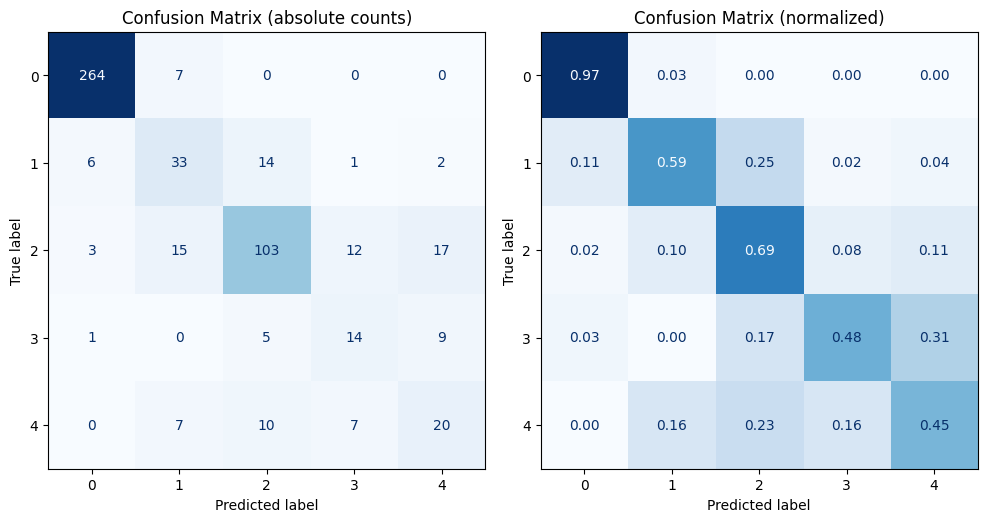


Hybrid ensemble (w=0.65):


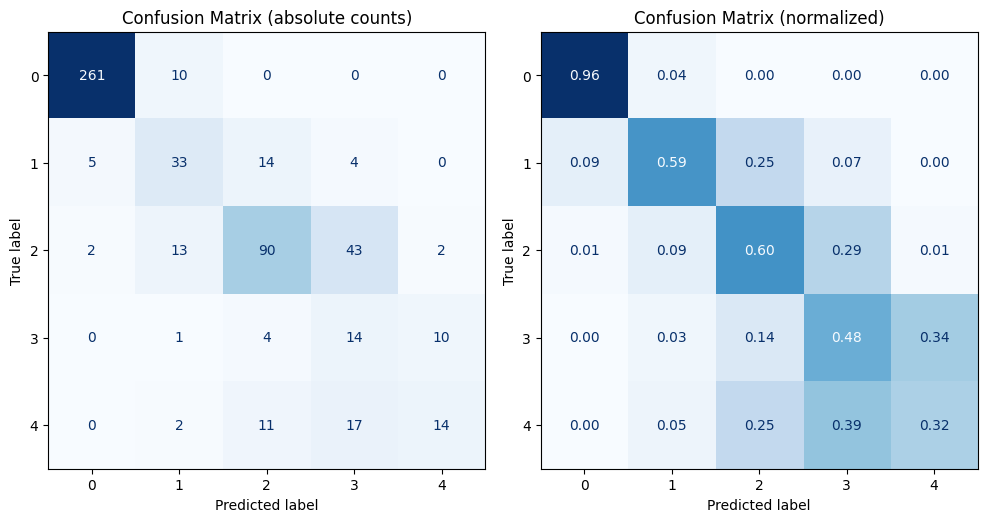

In [56]:
print("\nPure classification:")
plot_confusion_matrices(test_targets, np.argmax(test_probs_clf, axis=1), save=True, image_name="effnetb0_classification_cm_test")
print(f"\nHybrid ensemble (w={best_w}):")
plot_confusion_matrices(test_targets, test_ensemble_preds, save=True, image_name="effnetb0_ensemble_cm_test")

Even though pure classification shows higher recall for certain classes, the errors of the hybrid model are more tightly clustered around the main diagonal, leading to a higher QWK. The ensemble makes fewer large-scale errors, but as a classifier for exact classes, it is weaker.

### Statistical evaluation: Paired Bootstrap Test

To verify whether the ensemble's performance gain over pure classification is statistically significant rather than a random artifact of the test split, we conduct a **Paired Bootstrap Test**.

**Steps:**
1. Resample test set with replacement to create identical bootstrap subsets for both models.
2. Calculate QWK for both pure classification and ensemble on each subset.
3. Record the performance difference ($\Delta = \text{QWK}_{\text{ensemble}} - \text{QWK}_{\text{CE}}$) on each subset.
4. Compute the 95% confidence interval and mean difference.

If the lower bound of the interval is > 0, the improvement is statistically significant.

In [24]:
# Set random seed for reproducibility
np.random.seed(42)
n_bootstraps = 1000
qwk_diffs = []

# Get predictions for pure classification
preds_ce = np.argmax(test_probs_clf, axis=1)

# Run paired bootstrap iterations
for _ in range(n_bootstraps):
    # Generate identical random indices with replacement for both models
    indices = resample(np.arange(len(test_targets)), replace=True)

    t_true = test_targets[indices]
    t_ce = preds_ce[indices]
    t_ens = test_ensemble_preds[indices]

    # Compute QWK for both models on the current bootstrap sample
    qwk_ce = cohen_kappa_score(t_true, t_ce, weights='quadratic')
    qwk_ens = cohen_kappa_score(t_true, t_ens, weights='quadratic')

    # Store the performance difference
    qwk_diffs.append(qwk_ens - qwk_ce)

# Compute mean diff and 95% confidence interval for diffs
qwk_diffs = np.array(qwk_diffs)
ci_lower = np.percentile(qwk_diffs, 2.5)
ci_upper = np.percentile(qwk_diffs, 97.5)
mean_diff = np.mean(qwk_diffs)

print(f"Mean QWK difference (Ensemble - CE): {mean_diff:.4f}")
print(f"Paired Bootstrap confidence interval (95%): [{ci_lower:.4f}, {ci_upper:.4f}]")

if ci_lower > 0:
    print("Conclusion: The ensemble's superiority is statistically significant (95% CI excludes 0).")
else:
    print("Conclusion: No statistically significant difference.")

Mean QWK difference (Ensemble - CE): 0.0371
Paired Bootstrap confidence interval (95%): [0.0176, 0.0585]
Conclusion: The ensemble's superiority is statistically significant (95% CI excludes 0).


Since the lower bound of the confidence interval is greater than zero, the superiority of the hybrid ensemble over the pure classification is statistically significant.

Note:
1. Decision rule declared before the test run: accept the ensemble if its test QWK ≥ CE − 0.01 (passed, +0.037). The paired bootstrap above was added afterwards as an additional check: 95% CI of the difference [0.018, 0.059] excludes both 0 and 0.01.
2. CI reflects test data variance only (not training seed variance).